# Palangka Raya, Sebangau and Kundangan AOIs and Sentinel-1 composites

Plots the AOIs on a basemap and the Sentinel-1 RTC composites (Earthdata, 30 m) made by `job/composite` as RGB: R = VV, G = VH, B = (VV - VH) / (VV + VH).

In [1]:
import os

os.chdir(os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebook" else os.getcwd())

import contextily as cx
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from dotenv import load_dotenv
from matplotlib.ticker import FuncFormatter

# override=True so the .env credentials win over anything already in the environment
load_dotenv(override=True)

AOI_PATHS = {
    "palangka_raya": "input/palangka_raya.geojson",
    "sebangau": "input/sebangau.geojson",
    "kundangan": "input/kundangan.geojson",
}
S1_PREFIX = "gs://gee-ramiqcom-s4g-bucket/forest_fire_indonesian_2026/s1"
S1_DATES = ["2026-06", "2026-10"]

## Map helpers

In [2]:
def add_lonlat(ax):
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{abs(x):.2f}°{'E' if x >= 0 else 'W'}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{abs(y):.2f}°{'N' if y >= 0 else 'S'}"))
    ax.tick_params(labelsize=8)
    ax.grid(color="white", linewidth=0.4, alpha=0.6, linestyle="--")


def add_north_arrow(ax, x=0.94, y=0.92):
    ax.annotate(
        "N",
        xy=(x, y),
        xytext=(x, y - 0.1),
        xycoords="axes fraction",
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        arrowprops=dict(facecolor="black", edgecolor="white", width=4, headwidth=12),
    )


def add_scalebar(ax, x=0.05, y=0.05):
    # Axes are in degrees, so convert km to degrees of longitude at the map's center latitude
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    km_per_deg = 111.32 * np.cos(np.radians((ymin + ymax) / 2))
    width_km = (xmax - xmin) * km_per_deg
    length_km = next(n for n in (50, 20, 10, 5, 2, 1, 0.5) if n <= width_km / 4)
    length_deg = length_km / km_per_deg

    x0 = xmin + x * (xmax - xmin)
    y0 = ymin + y * (ymax - ymin)
    height = (ymax - ymin) * 0.012
    for i in range(2):
        ax.add_patch(
            plt.Rectangle(
                (x0 + i * length_deg / 2, y0),
                length_deg / 2,
                height,
                facecolor="black" if i == 0 else "white",
                edgecolor="black",
                linewidth=0.8,
            )
        )
    for frac in (0, 0.5, 1):
        ax.text(
            x0 + frac * length_deg,
            y0 + height * 1.6,
            f"{length_km * frac:g}",
            ha="center",
            va="bottom",
            fontsize=8,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1),
        )
    ax.text(x0 + length_deg + (xmax - xmin) * 0.01, y0, "km", va="bottom", fontsize=8)


def decorate(ax, title):
    add_lonlat(ax)
    add_north_arrow(ax)
    add_scalebar(ax)
    ax.set_title(title)

## 1. Load AOIs

In [3]:
aois = {name: gpd.read_file(path).to_crs("EPSG:4326") for name, path in AOI_PATHS.items()}
for name, aoi in aois.items():
    print(name, aoi.crs, aoi.total_bounds)

palangka_raya EPSG:4326 [113.55933468  -2.58318144 114.21626255  -1.90399978]
sebangau EPSG:4326 [113.42354492  -2.83089901 113.94251448  -2.35257769]
kundangan EPSG:4326 [110.90339112  -1.76322128 111.16930255  -1.49484948]


## 2. Plot AOIs with basemap

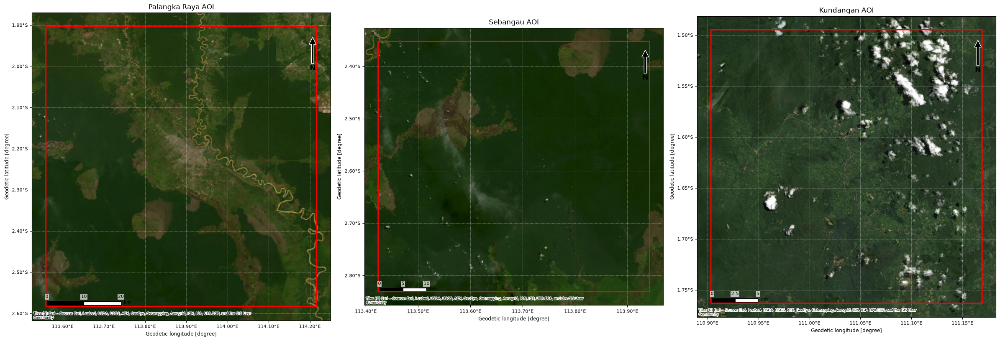

In [4]:
fig, axes = plt.subplots(1, len(aois), figsize=(8 * len(aois), 8))

for ax, (name, aoi) in zip(np.atleast_1d(axes), aois.items()):
    aoi.boundary.plot(ax=ax, color="red", linewidth=2)

    xmin, ymin, xmax, ymax = aoi.total_bounds
    pad = 0.05 * max(xmax - xmin, ymax - ymin)
    ax.set_xlim(xmin - pad, xmax + pad)
    ax.set_ylim(ymin - pad, ymax + pad)
    cx.add_basemap(ax, crs=aoi.crs, source=cx.providers.Esri.WorldImagery, attribution_size=6)

    decorate(ax, f"{name.replace('_', ' ').title()} AOI")

plt.tight_layout()
plt.show()

## 3. Sentinel-1 composites as RGB

R = VV, G = VH, B = (VV - VH) / (VV + VH). Each channel uses one display range for all plots, the 2nd to 98th percentile of the valid pixels of all composites pooled, so colors are comparable between AOIs and dates.

In [5]:
def load_s1(path):
    with rasterio.open(path) as src:
        data = src.read().astype("float32")
        names = [name.lower() for name in src.descriptions]
        bounds = src.bounds
        nodata = src.nodata or 0

    vv = data[names.index("vv")]
    vh = data[names.index("vh")]
    valid = (vv != nodata) & (vh != nodata)
    ratio = np.where(valid, (vv - vh) / np.where(valid, vv + vh, 1), 0)

    extent = (bounds.left, bounds.right, bounds.bottom, bounds.top)
    return np.stack([vv, vh, ratio]), valid, extent


s1 = {
    (name, date): load_s1(f"{S1_PREFIX}/{name}_{date}.tif")
    for name in aois
    for date in S1_DATES
}

# One display range per channel, from the valid pixels of all composites together
ranges = [
    np.percentile(np.concatenate([bands[i][valid] for bands, valid, _ in s1.values()]), [2, 98])
    for i in range(3)
]
for channel, (lo, hi) in zip(["VV", "VH", "(VV-VH)/(VV+VH)"], ranges):
    print(f"{channel}: {lo:.3f} to {hi:.3f}")


def to_rgba(bands, valid):
    rgb = np.dstack([np.clip((band - lo) / (hi - lo), 0, 1) for band, (lo, hi) in zip(bands, ranges)])
    return np.dstack([rgb, valid.astype("float32")])

VV: 798.000 to 3388.000
VH: 169.000 to 807.000
(VV-VH)/(VV+VH): 0.458 to 0.725


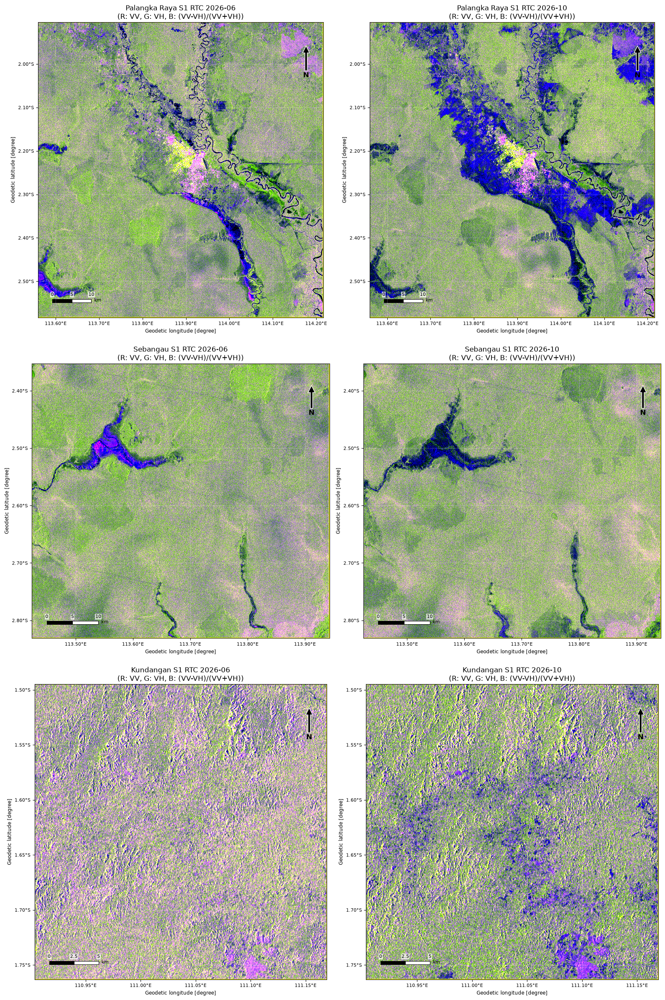

In [6]:
fig, axes = plt.subplots(
    len(aois), len(S1_DATES), figsize=(8 * len(S1_DATES), 8 * len(aois)), squeeze=False
)

for row, (name, aoi) in zip(axes, aois.items()):
    for ax, date in zip(row, S1_DATES):
        bands, valid, extent = s1[(name, date)]
        ax.imshow(to_rgba(bands, valid), extent=extent, interpolation="nearest")
        aoi.boundary.plot(ax=ax, color="yellow", linewidth=1.5)
        ax.set_xlim(extent[0], extent[1])
        ax.set_ylim(extent[2], extent[3])
        decorate(
            ax,
            f"{name.replace('_', ' ').title()} S1 RTC {date}\n(R: VV, G: VH, B: (VV-VH)/(VV+VH))",
        )

plt.tight_layout()
plt.show()